#### Task 1: Generate 1000 normally distributed numbers (mean 500, SD 100) and plot their distribution.

Generated 1000 numbers from Normal(mean = 500, SD = 100)
First 10 values : [534.6, 582.2, 533.0, 369.7, 590.5, 544.6, 446.3, 558.1, 536.5, 529.4]
Sample mean     = 494.57  (target 500)
Sample SD       = 98.68  (target 100)
Min / Max       = 145.1 / 875.2
Within 1 SD of the mean: 69.9%  (theory 68.3%)
Within 2 SD of the mean: 95.5%  (theory 95.4%)


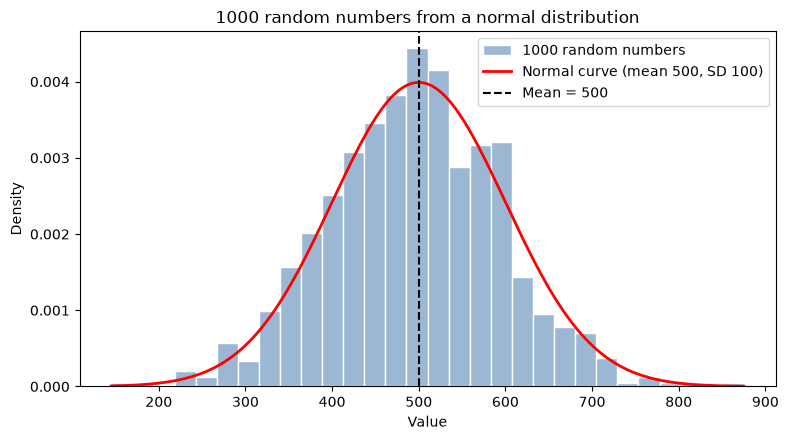

Plot saved to normal_distribution.png


In [2]:
import os
import numpy as np
import matplotlib
if "__file__" in globals():            # plain script: save to file; notebook: show inline
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
from scipy import stats
 
HERE = os.path.dirname(os.path.abspath(__file__)) if "__file__" in globals() else os.getcwd()
 
mu, sigma, n = 500, 100, 1000
rng = np.random.default_rng(seed=1)
data = rng.normal(loc=mu, scale=sigma, size=n)
 
print(f"Generated {n} numbers from Normal(mean = {mu}, SD = {sigma})")
print(f"First 10 values : {np.round(data[:10], 1).tolist()}")
print(f"Sample mean     = {data.mean():.2f}  (target {mu})")
print(f"Sample SD       = {data.std(ddof=1):.2f}  (target {sigma})")
print(f"Min / Max       = {data.min():.1f} / {data.max():.1f}")
within1 = np.mean(np.abs(data - mu) <= sigma)
within2 = np.mean(np.abs(data - mu) <= 2 * sigma)
print(f"Within 1 SD of the mean: {within1:.1%}  (theory 68.3%)")
print(f"Within 2 SD of the mean: {within2:.1%}  (theory 95.4%)")
 
plt.figure(figsize=(8, 4.5))
plt.hist(data, bins=30, density=True, color="#9bb7d4", edgecolor="white", label="1000 random numbers")
x = np.linspace(data.min(), data.max(), 300)
plt.plot(x, stats.norm.pdf(x, mu, sigma), color="red", lw=2, label="Normal curve (mean 500, SD 100)")
plt.axvline(mu, color="black", ls="--", label="Mean = 500")
plt.xlabel("Value")
plt.ylabel("Density")
plt.title("1000 random numbers from a normal distribution")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(HERE, "normal_distribution.png"), dpi=150)
if "__file__" not in globals():
    plt.show()
print("Plot saved to normal_distribution.png")